# Implementasi Python pada Permasalahan Probabilitas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mirna-HZ/ProbabilitasStatistika_Python_Mirna/blob/main/Tugas_Eksplorasi_Python/01_Permasalahan_Probabilitas.ipynb)

## Import Library

In [1]:
import math
import random
import itertools
from fractions import Fraction
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from sympy.stats import Die, P, E, variance

rng = np.random.default_rng(42)   # seed agar hasil simulasi bisa diulang
random.seed(42)

## P1. Ruang Sampel dan Probabilitas Klasik: String 4 Bit Acak

**Soal:** Sebuah generator menghasilkan string 4 bit secara acak, dan setiap bit bernilai 0 atau 1 dengan peluang sama. Tentukan ruang sampel, peluang string berisi tepat dua bit 1, dan peluang bit pertama sama dengan bit terakhir, lalu bandingkan dengan simulasi 100.000 string.

**Perhitungan manual:**

- Ruang sampel berisi 2^4 = 16 string, dari 0000 sampai 1111.
- Banyak string dengan tepat dua bit 1 = C(4,2) = 6, sehingga P = 6/16 = 3/8 = 0,375.
- Bit pertama sama dengan bit terakhir: bit pertama bebas (2 pilihan), bit terakhir mengikuti, dua bit tengah bebas (4 pilihan), sehingga 8 string dan P = 8/16 = 1/2.

Banyak titik sampel : 16
Kejadian A (dua bit 1): ['0011', '0101', '0110', '1001', '1010', '1100']
P(A) = 3/8 = 0.375
P(B) = 1/2

Simulasi P(A) = 0.3754
Simulasi P(B) = 0.5011


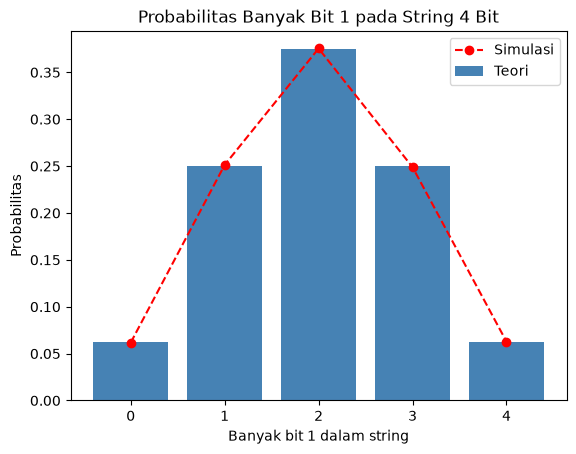

In [2]:
# Ruang sampel string 4 bit
ruang_sampel = ["".join(b) for b in itertools.product("01", repeat=4)]
A = [s for s in ruang_sampel if s.count("1") == 2]
B = [s for s in ruang_sampel if s[0] == s[-1]]

print("Banyak titik sampel :", len(ruang_sampel))
print("Kejadian A (dua bit 1):", A)
print("P(A) =", Fraction(len(A), len(ruang_sampel)), "=", len(A) / len(ruang_sampel))
print("P(B) =", Fraction(len(B), len(ruang_sampel)))

# Simulasi 100.000 string 4 bit
n = 100_000
bit = rng.integers(0, 2, size=(n, 4))
jumlah_satu = bit.sum(axis=1)
print("\nSimulasi P(A) =", round(np.mean(jumlah_satu == 2), 4))
print("Simulasi P(B) =", round(np.mean(bit[:, 0] == bit[:, 3]), 4))

# Distribusi banyak bit 1: teori vs simulasi
frek = Counter(s.count("1") for s in ruang_sampel)
x = sorted(frek)
plt.bar(x, [frek[k] / 16 for k in x], color="steelblue", label="Teori")
plt.plot(x, [np.mean(jumlah_satu == k) for k in x], "ro--", label="Simulasi")
plt.xticks(x)
plt.xlabel("Banyak bit 1 dalam string")
plt.ylabel("Probabilitas")
plt.title("Probabilitas Banyak Bit 1 pada String 4 Bit")
plt.legend()
plt.show()

## P2. Probabilitas Simbolik dan Bersyarat dengan sympy.stats: Dua Dadu 8 Sisi

**Soal:** Sebuah game memakai dua dadu 8 sisi, X dan Y. Hitung secara eksak P(X + Y > 12), P(X + Y > 12 | X = 8), P(X = Y), nilai harapan E(X + Y), dan varians Var(X + Y) memakai modul sympy.stats, lalu verifikasi dengan enumerasi ruang sampel.

**Perhitungan manual:**

- Ruang sampel berisi 8 x 8 = 64 titik. X + Y > 12 terjadi pada jumlah 13 (4 titik), 14 (3 titik), 15 (2 titik), dan 16 (1 titik), sehingga P = 10/64 = 5/32.
- Jika X = 8, syaratnya Y > 4, yaitu Y = 5, 6, 7, 8, sehingga P = 4/8 = 1/2.
- X = Y terjadi pada 8 titik, sehingga P = 8/64 = 1/8.
- E(X) = (1 + 8)/2 = 4,5 sehingga E(X + Y) = 9. Var(X) = (8^2 - 1)/12 = 21/4 sehingga Var(X + Y) = 21/2 (X dan Y saling bebas).

In [3]:
X, Y = Die("X", 8), Die("Y", 8)
S = X + Y

print("P(X + Y > 12)         =", P(S > 12))
print("P(X + Y > 12 | X = 8) =", P(S > 12, sp.Eq(X, 8)))
print("P(X = Y)              =", P(sp.Eq(X, Y)))
print("E(X + Y)              =", E(S))
print("Var(X + Y)            =", variance(S), "=", float(variance(S)))

# Verifikasi dengan enumerasi ruang sampel
rs = list(itertools.product(range(1, 9), repeat=2))
print("\nVerifikasi enumerasi:")
print("P(X + Y > 12)         =", Fraction(sum(a + b > 12 for a, b in rs), len(rs)))
x8 = [(a, b) for a, b in rs if a == 8]
print("P(X + Y > 12 | X = 8) =", Fraction(sum(a + b > 12 for a, b in x8), len(x8)))
print("P(X = Y)              =", Fraction(sum(a == b for a, b in rs), len(rs)))

P(X + Y > 12)         = 5/32
P(X + Y > 12 | X = 8) = 1/2
P(X = Y)              = 1/8
E(X + Y)              = 9
Var(X + Y)            = 21/2 = 10.5

Verifikasi enumerasi:
P(X + Y > 12)         = 5/32
P(X + Y > 12 | X = 8) = 1/2
P(X = Y)              = 1/8


## P3. Permutasi dan Kombinasi: Kode Akses dan Tim Hackathon

**Soal:** (a) Sebuah sistem membuat kode akses 5 huruf kapital (A sampai Z) tanpa huruf berulang. Berapa banyak kode yang mungkin dan berapa peluang kode tertentu terpilih secara acak? (b) Dari 12 mahasiswa (5 desainer UI/UX dan 7 developer) dipilih 4 orang secara acak untuk tim hackathon. Berapa peluang tim berisi tepat 2 desainer?

**Perhitungan manual:**

- (a) Urutan huruf diperhatikan sehingga dipakai permutasi 26P5 = 26 x 25 x 24 x 23 x 22 = 7.893.600 kode. Peluang satu kode tertentu = 1/7.893.600.
- (b) Banyak tim = C(12,4) = 495. Tim dengan tepat 2 desainer = C(5,2) x C(7,2) = 10 x 21 = 210.
- P(tepat 2 desainer) = 210/495 = 14/33 = 0,4242.

Banyak kode akses           : 7893600
Peluang satu kode tertentu  : 1/7893600

Banyak tim yang mungkin      : 495
Contoh tim 2 desainer        : [('D1', 'D2', 'V1', 'V2'), ('D1', 'D2', 'V1', 'V3')]
P(tepat 2 desainer) rumus    : 14/33 = 0.4242
P(tepat 2 desainer) enumerasi: 14/33


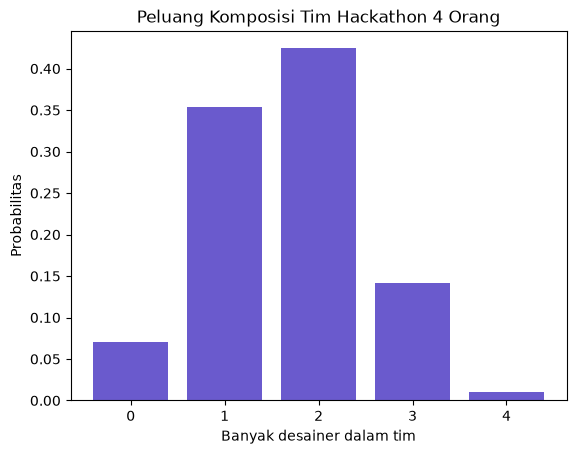

In [4]:
# a) Kode akses 5 huruf tanpa pengulangan -> permutasi 26P5
banyak_kode = math.perm(26, 5)
print("Banyak kode akses           :", banyak_kode)
print("Peluang satu kode tertentu  :", Fraction(1, banyak_kode))

# b) Tim 4 orang dari 5 desainer (D) dan 7 developer (V)
mahasiswa = [f"D{i}" for i in range(1, 6)] + [f"V{i}" for i in range(1, 8)]
semua_tim = list(itertools.combinations(mahasiswa, 4))
tim_2_desainer = [t for t in semua_tim if sum(m.startswith("D") for m in t) == 2]

p_rumus = Fraction(math.comb(5, 2) * math.comb(7, 2), math.comb(12, 4))
p_enum = Fraction(len(tim_2_desainer), len(semua_tim))
print("\nBanyak tim yang mungkin      :", len(semua_tim))
print("Contoh tim 2 desainer        :", tim_2_desainer[:2])
print("P(tepat 2 desainer) rumus    :", p_rumus, "=", round(float(p_rumus), 4))
print("P(tepat 2 desainer) enumerasi:", p_enum)

# Peluang tiap banyak desainer dalam tim (0 sampai 4)
peluang = [math.comb(5, k) * math.comb(7, 4 - k) / math.comb(12, 4) for k in range(5)]
plt.bar(range(5), peluang, color="slateblue")
plt.xticks(range(5))
plt.xlabel("Banyak desainer dalam tim")
plt.ylabel("Probabilitas")
plt.title("Peluang Komposisi Tim Hackathon 4 Orang")
plt.show()

## P4. Aturan Komplemen dan Inklusi-Eksklusi: Kekuatan Password Acak

**Soal:** Sebuah generator membuat password 8 karakter. Setiap karakter dipilih acak dari 62 karakter (26 huruf kecil, 26 huruf kapital, dan 10 angka). Tentukan peluang password memuat minimal satu angka, dan peluang password memuat minimal satu angka sekaligus minimal satu huruf kapital. Bandingkan dengan simulasi dan lihat pengaruh panjang password.

**Perhitungan manual:**

- Komplemen: P(tanpa angka) = (52/62)^8 = 0,2448, sehingga P(minimal satu angka) = 1 - 0,2448 = 0,7552.
- Misalkan A = tanpa angka dan K = tanpa huruf kapital. P(A) = (52/62)^8 = 0,2448, P(K) = (36/62)^8 = 0,0129, P(A dan K) = (26/62)^8 = 0,00096.
- Inklusi-eksklusi: P(A atau K) = 0,2448 + 0,0129 - 0,00096 = 0,2568, sehingga P(minimal satu angka dan minimal satu kapital) = 1 - 0,2568 = 0,7432.

P(minimal satu angka)                 = 0.7552
P(minimal satu angka dan satu kapital) = 0.7432

Simulasi P(minimal satu angka)         = 0.7529
Simulasi P(angka dan kapital)          = 0.7412


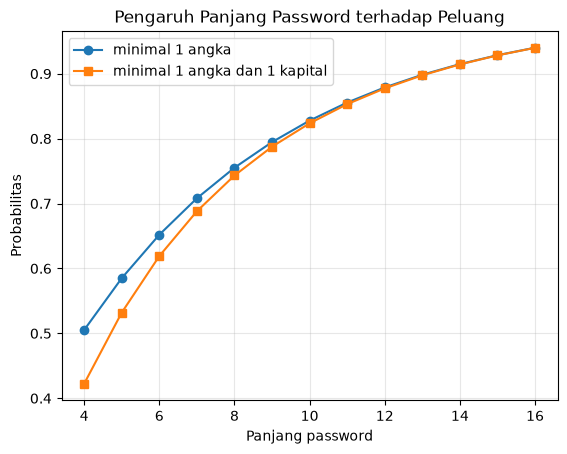

In [5]:
def p_aman(panjang):
    p_tanpa_angka = (52 / 62) ** panjang
    p_tanpa_kapital = (36 / 62) ** panjang
    p_tanpa_keduanya = (26 / 62) ** panjang
    p_min_angka = 1 - p_tanpa_angka
    p_lengkap = 1 - (p_tanpa_angka + p_tanpa_kapital - p_tanpa_keduanya)
    return p_min_angka, p_lengkap

p1, p2 = p_aman(8)
print(f"P(minimal satu angka)                 = {p1:.4f}")
print(f"P(minimal satu angka dan satu kapital) = {p2:.4f}")

# Simulasi 100.000 password: 0-25 huruf kecil, 26-51 kapital, 52-61 angka
n = 100_000
pw = rng.integers(0, 62, size=(n, 8))
ada_kapital = ((pw >= 26) & (pw < 52)).any(axis=1)
ada_angka = (pw >= 52).any(axis=1)
print(f"\nSimulasi P(minimal satu angka)         = {ada_angka.mean():.4f}")
print(f"Simulasi P(angka dan kapital)          = {(ada_angka & ada_kapital).mean():.4f}")

panjang = np.arange(4, 17)
hasil = np.array([p_aman(k) for k in panjang])
plt.plot(panjang, hasil[:, 0], "o-", label="minimal 1 angka")
plt.plot(panjang, hasil[:, 1], "s-", label="minimal 1 angka dan 1 kapital")
plt.xlabel("Panjang password")
plt.ylabel("Probabilitas")
plt.title("Pengaruh Panjang Password terhadap Peluang")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## P5. Probabilitas Bersyarat dari Data Log Server

**Soal:** Sebuah server mencatat 500 request dengan rincian: GET 280 sukses dan 20 gagal, POST 120 sukses dan 30 gagal, PUT 40 sukses dan 10 gagal. Tentukan P(Gagal), P(Gagal | POST), P(POST | Gagal), P(Gagal | GET), lalu periksa apakah kejadian gagal saling bebas terhadap metode request.

**Perhitungan manual:**

- Total gagal = 20 + 30 + 10 = 60, sehingga P(Gagal) = 60/500 = 0,12.
- P(Gagal | POST) = 30/150 = 0,20 dan P(Gagal | GET) = 20/300 = 0,0667.
- P(POST | Gagal) = 30/60 = 0,50.
- Karena P(Gagal | POST) tidak sama dengan P(Gagal), kejadian gagal tidak saling bebas terhadap metode request.

Tabel kontingensi:
status  Gagal  Sukses  Total
metode                      
GET        20     280    300
POST       30     120    150
PUT        10      40     50
Total      60     440    500 

P(Gagal)        = 0.1200
P(Gagal | POST) = 0.2000
P(POST | Gagal) = 0.5000
P(Gagal | GET)  = 0.0667
Saling bebas?   = False


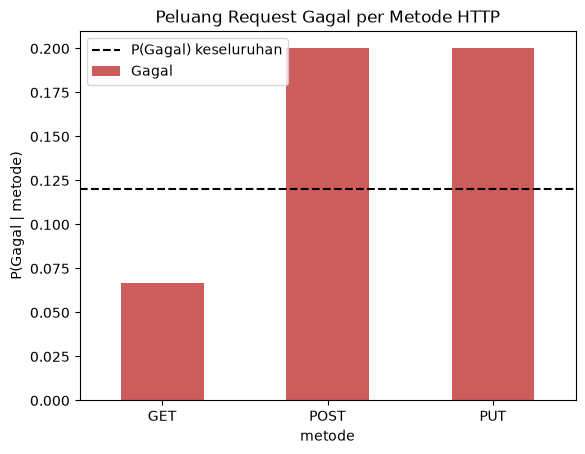

In [6]:
# Membentuk data log 500 request dari tabel frekuensi
frek = {("GET", "Sukses"): 280, ("GET", "Gagal"): 20,
        ("POST", "Sukses"): 120, ("POST", "Gagal"): 30,
        ("PUT", "Sukses"): 40, ("PUT", "Gagal"): 10}
baris = [k for k, v in frek.items() for _ in range(v)]
log = pd.DataFrame(baris, columns=["metode", "status"])

tabel = pd.crosstab(log["metode"], log["status"], margins=True, margins_name="Total")
print("Tabel kontingensi:")
print(tabel, "\n")

p_gagal = (log["status"] == "Gagal").mean()
p_gagal_post = (log[log["metode"] == "POST"]["status"] == "Gagal").mean()
p_post_gagal = (log[log["status"] == "Gagal"]["metode"] == "POST").mean()
p_gagal_get = (log[log["metode"] == "GET"]["status"] == "Gagal").mean()

print(f"P(Gagal)        = {p_gagal:.4f}")
print(f"P(Gagal | POST) = {p_gagal_post:.4f}")
print(f"P(POST | Gagal) = {p_post_gagal:.4f}")
print(f"P(Gagal | GET)  = {p_gagal_get:.4f}")
print("Saling bebas?   =", np.isclose(p_gagal_post, p_gagal))

# Peluang gagal untuk tiap metode (normalisasi per baris)
gagal_per_metode = pd.crosstab(log["metode"], log["status"], normalize="index")["Gagal"]
gagal_per_metode.plot(kind="bar", color="indianred")
plt.axhline(p_gagal, linestyle="--", color="black", label="P(Gagal) keseluruhan")
plt.ylabel("P(Gagal | metode)")
plt.title("Peluang Request Gagal per Metode HTTP")
plt.xticks(rotation=0)
plt.legend()
plt.show()

## P6. Kejadian Saling Bebas: Keandalan Sistem Seri dan Paralel

**Soal:** Sebuah aplikasi web terdiri dari load balancer (peluang hidup 0,99), dua server aplikasi yang dipasang paralel (masing-masing 0,90), dan satu database (0,95) yang tersusun seri. Komponen bekerja saling bebas. Hitung peluang sistem hidup, bandingkan dengan simulasi, dan lihat pengaruh jumlah server paralel.

**Perhitungan manual:**

- Blok paralel hidup jika minimal satu server hidup: 1 - (1 - 0,90)^2 = 0,99.
- Sistem seri hidup jika semua blok hidup: 0,99 x 0,99 x 0,95 = 0,931095.
- Jika hanya ada satu server: 0,99 x 0,90 x 0,95 = 0,84645.

P(blok server paralel hidup)  = 0.9900
P(sistem hidup) teori         = 0.931095
P(sistem hidup) simulasi      = 0.930987
P(sistem hidup) jika 1 server = 0.846450
  1 server paralel -> keandalan 0.846450
  2 server paralel -> keandalan 0.931095
  3 server paralel -> keandalan 0.939559
  4 server paralel -> keandalan 0.940406
  5 server paralel -> keandalan 0.940491


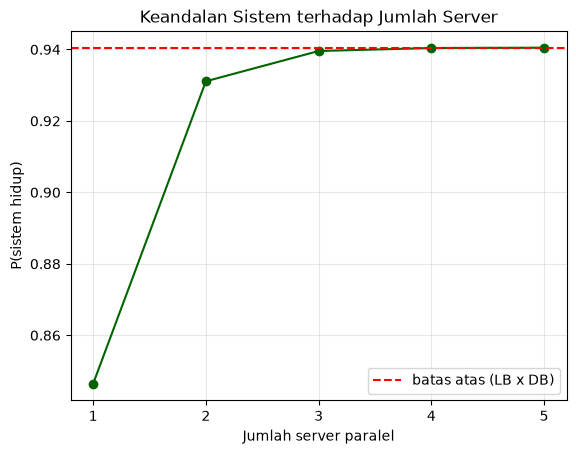

In [7]:
p_lb, p_server, p_db = 0.99, 0.90, 0.95

# Teori: LB seri (Server1 paralel Server2) seri DB
p_paralel = 1 - (1 - p_server) ** 2
p_sistem = p_lb * p_paralel * p_db
print(f"P(blok server paralel hidup)  = {p_paralel:.4f}")
print(f"P(sistem hidup) teori         = {p_sistem:.6f}")

# Simulasi 1.000.000 hari operasi
n = 1_000_000
lb = rng.random(n) < p_lb
s1 = rng.random(n) < p_server
s2 = rng.random(n) < p_server
db = rng.random(n) < p_db
hidup = lb & (s1 | s2) & db
print(f"P(sistem hidup) simulasi      = {hidup.mean():.6f}")
print(f"P(sistem hidup) jika 1 server = {p_lb * p_server * p_db:.6f}")

# Pengaruh jumlah server paralel terhadap keandalan
k = np.arange(1, 6)
r = p_lb * (1 - (1 - p_server) ** k) * p_db
for ki, ri in zip(k, r):
    print(f"  {ki} server paralel -> keandalan {ri:.6f}")
plt.plot(k, r, "o-", color="darkgreen")
plt.axhline(p_lb * p_db, color="red", linestyle="--", label="batas atas (LB x DB)")
plt.xticks(k)
plt.xlabel("Jumlah server paralel")
plt.ylabel("P(sistem hidup)")
plt.title("Keandalan Sistem terhadap Jumlah Server")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## P7. Teorema Probabilitas Total dan Teorema Bayes: Crash Aplikasi per Versi Android

**Soal:** Pengguna sebuah aplikasi mobile tersebar pada empat versi Android: Android 14 (40%), Android 13 (25%), Android 12 (20%), dan Android 11 (15%). Peluang aplikasi crash pada masing-masing versi adalah 1%, 2%, 3%, dan 5%. Tentukan peluang sebuah sesi mengalami crash, lalu jika diketahui terjadi crash, tentukan peluang sesi tersebut berasal dari masing-masing versi.

**Perhitungan manual:**

- Probabilitas total: P(C) = 0,40(0,01) + 0,25(0,02) + 0,20(0,03) + 0,15(0,05) = 0,004 + 0,005 + 0,006 + 0,0075 = 0,0225.
- Bayes: P(Android 14 | C) = 0,004/0,0225 = 0,1778 dan P(Android 13 | C) = 0,005/0,0225 = 0,2222.
- P(Android 12 | C) = 0,006/0,0225 = 0,2667 dan P(Android 11 | C) = 0,0075/0,0225 = 0,3333.

            prior  p_crash  prior x likelihood  posterior
Android 14   0.40     0.01              0.0040     0.1778
Android 13   0.25     0.02              0.0050     0.2222
Android 12   0.20     0.03              0.0060     0.2667
Android 11   0.15     0.05              0.0075     0.3333

P(crash) total = 0.0225
P(crash) eksak              = 9/400
P(Android 11 | crash) eksak = 1/3


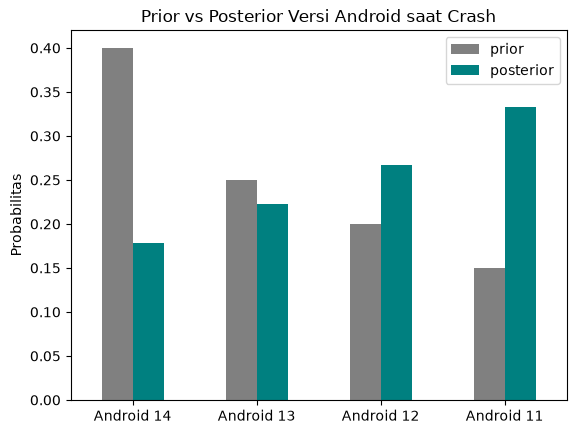

In [8]:
versi = pd.DataFrame({
    "prior": [0.40, 0.25, 0.20, 0.15],    # P(versi)
    "p_crash": [0.01, 0.02, 0.03, 0.05]   # P(crash | versi)
}, index=["Android 14", "Android 13", "Android 12", "Android 11"])

versi["prior x likelihood"] = versi["prior"] * versi["p_crash"]
p_crash_total = versi["prior x likelihood"].sum()                 # probabilitas total
versi["posterior"] = versi["prior x likelihood"] / p_crash_total   # teorema Bayes
print(versi.round(4))
print("\nP(crash) total =", round(p_crash_total, 4))

# Versi pecahan eksak dengan sympy
prior = [sp.Rational(40, 100), sp.Rational(25, 100), sp.Rational(20, 100), sp.Rational(15, 100)]
crash = [sp.Rational(1, 100), sp.Rational(2, 100), sp.Rational(3, 100), sp.Rational(5, 100)]
pC = sum(a * b for a, b in zip(prior, crash))
print("P(crash) eksak              =", pC)
print("P(Android 11 | crash) eksak =", prior[3] * crash[3] / pC)

versi[["prior", "posterior"]].plot(kind="bar", color=["gray", "teal"])
plt.ylabel("Probabilitas")
plt.title("Prior vs Posterior Versi Android saat Crash")
plt.xticks(rotation=0)
plt.show()

## P8. Teorema Bayes Bertahap: Deteksi Akun Bot di Media Sosial

**Soal:** Sebanyak 20% akun pada sebuah platform adalah bot. Ciri "akun baru" (umur kurang dari 7 hari) ditemukan pada 70% bot dan 10% akun manusia. Ciri "posting lebih dari 50 kali per hari" ditemukan pada 60% bot dan 5% akun manusia, dan kedua ciri dianggap saling bebas bila jenis akun diketahui. Tentukan P(bot | akun baru) dan P(bot | akun baru dan posting tinggi), lalu verifikasi dengan simulasi 200.000 akun.

**Perhitungan manual:**

- P(bot | baru) = (0,2 x 0,7) / (0,2 x 0,7 + 0,8 x 0,1) = 0,14 / 0,22 = 0,6364.
- Posterior 0,6364 menjadi prior baru untuk ciri posting tinggi:
- P(bot | baru, posting tinggi) = (0,6364 x 0,6) / (0,6364 x 0,6 + 0,3636 x 0,05) = 0,3818 / 0,4 = 0,9545.

P(bot | akun baru)                 = 0.6364
P(bot | akun baru, posting tinggi) = 0.9545

Simulasi P(bot | akun baru)                 = 0.6323
Simulasi P(bot | akun baru, posting tinggi) = 0.9526


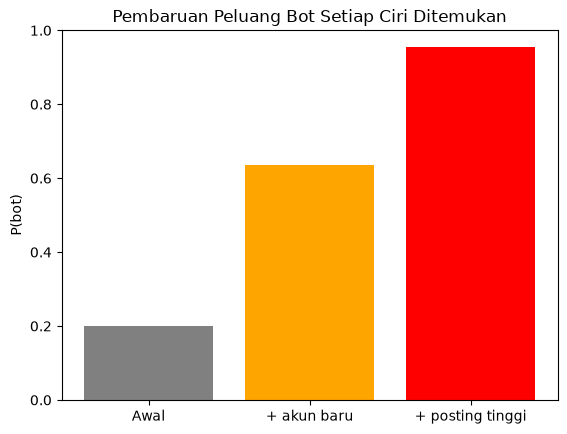

In [9]:
p_bot = 0.20
p_baru = {"bot": 0.70, "manusia": 0.10}
p_posting = {"bot": 0.60, "manusia": 0.05}

def bayes(prior, like_bot, like_manusia):
    pembilang = prior * like_bot
    return pembilang / (pembilang + (1 - prior) * like_manusia)

post1 = bayes(p_bot, p_baru["bot"], p_baru["manusia"])
post2 = bayes(post1, p_posting["bot"], p_posting["manusia"])   # posterior jadi prior baru
print(f"P(bot | akun baru)                 = {post1:.4f}")
print(f"P(bot | akun baru, posting tinggi) = {post2:.4f}")

# Verifikasi dengan simulasi 200.000 akun
n = 200_000
is_bot = rng.random(n) < p_bot
baru = np.where(is_bot, rng.random(n) < 0.70, rng.random(n) < 0.10)
posting = np.where(is_bot, rng.random(n) < 0.60, rng.random(n) < 0.05)
print(f"\nSimulasi P(bot | akun baru)                 = {is_bot[baru].mean():.4f}")
print(f"Simulasi P(bot | akun baru, posting tinggi) = {is_bot[baru & posting].mean():.4f}")

plt.bar(["Awal", "+ akun baru", "+ posting tinggi"], [p_bot, post1, post2], color=["gray", "orange", "red"])
plt.ylim(0, 1)
plt.ylabel("P(bot)")
plt.title("Pembaruan Peluang Bot Setiap Ciri Ditemukan")
plt.show()

## P9. Teorema Bayes dari Sisi Penolakan: Face Unlock pada Smartphone

**Soal:** Fitur face unlock pada sebuah smartphone menerima pemilik dengan benar 98% kali, dan keliru menerima penyusup 3% kali. Dari seluruh percobaan membuka kunci, hanya 0,5% yang dilakukan penyusup. Jika sebuah percobaan ditolak, berapa peluang percobaan itu benar-benar dilakukan penyusup? Bagaimana pengaruh persentase penyusup terhadap hasil ini?

**Perhitungan manual:**

- P(ditolak | penyusup) = 1 - 0,03 = 0,97 dan P(ditolak | pemilik) = 1 - 0,98 = 0,02.
- P(ditolak) = 0,005 x 0,97 + 0,995 x 0,02 = 0,00485 + 0,0199 = 0,02475.
- P(penyusup | ditolak) = 0,00485 / 0,02475 = 0,1960. Artinya sekitar 80% penolakan justru dialami pemilik ponsel.

P(ditolak)               = 0.02475
P(penyusup | ditolak)    = 0.1960
P(pemilik | ditolak)     = 0.8040
P(penyusup | diterima)   = 0.000154
Penyusup 0.005 -> P(penyusup | ditolak) = 0.1960
Penyusup  0.02 -> P(penyusup | ditolak) = 0.4974
Penyusup   0.1 -> P(penyusup | ditolak) = 0.8435


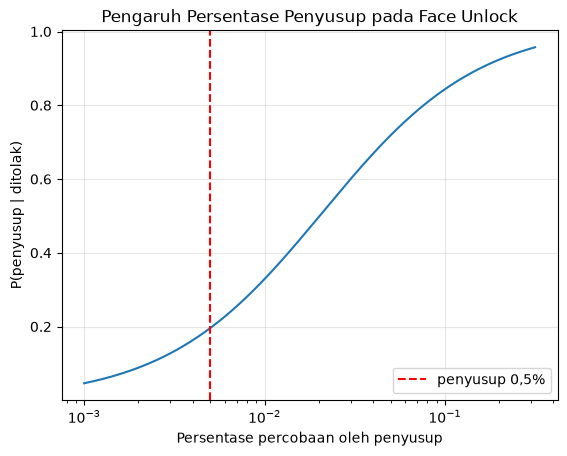

In [10]:
p_terima_pemilik, p_terima_penyusup = 0.98, 0.03
prev = 0.005   # P(penyusup)

p_tolak = prev * (1 - p_terima_penyusup) + (1 - prev) * (1 - p_terima_pemilik)
p_penyusup_tolak = prev * (1 - p_terima_penyusup) / p_tolak
p_terima = 1 - p_tolak
p_penyusup_terima = prev * p_terima_penyusup / p_terima
print(f"P(ditolak)               = {p_tolak:.5f}")
print(f"P(penyusup | ditolak)    = {p_penyusup_tolak:.4f}")
print(f"P(pemilik | ditolak)     = {1 - p_penyusup_tolak:.4f}")
print(f"P(penyusup | diterima)   = {p_penyusup_terima:.6f}")

for pv in [0.005, 0.02, 0.1]:
    post = pv * 0.97 / (pv * 0.97 + (1 - pv) * 0.02)
    print(f"Penyusup {pv:>5} -> P(penyusup | ditolak) = {post:.4f}")

prev_list = np.logspace(-3, -0.5, 200)
post_list = prev_list * 0.97 / (prev_list * 0.97 + (1 - prev_list) * 0.02)
plt.semilogx(prev_list, post_list)
plt.axvline(prev, color="red", linestyle="--", label="penyusup 0,5%")
plt.xlabel("Persentase percobaan oleh penyusup")
plt.ylabel("P(penyusup | ditolak)")
plt.title("Pengaruh Persentase Penyusup pada Face Unlock")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## P10. Simulasi Percobaan Acak: Masalah Monty Hall

**Soal:** Pada sebuah permainan terdapat 3 pintu, satu berisi hadiah. Pemain memilih satu pintu, lalu pembawa acara membuka satu pintu lain yang pasti kosong dan menawarkan pemain untuk pindah pilihan. Bandingkan peluang menang strategi tetap dan strategi pindah memakai simulasi 100.000 permainan.

**Perhitungan manual:**

- Strategi tetap menang hanya jika pilihan awal benar: P = 1/3.
- Strategi pindah menang jika pilihan awal salah (peluang 2/3), karena pintu kosong lain sudah dibuka: P = 2/3.

P(menang | tetap)  simulasi = 0.3325  (teori 1/3 = 0.3333)
P(menang | pindah) simulasi = 0.6667  (teori 2/3 = 0.6667)


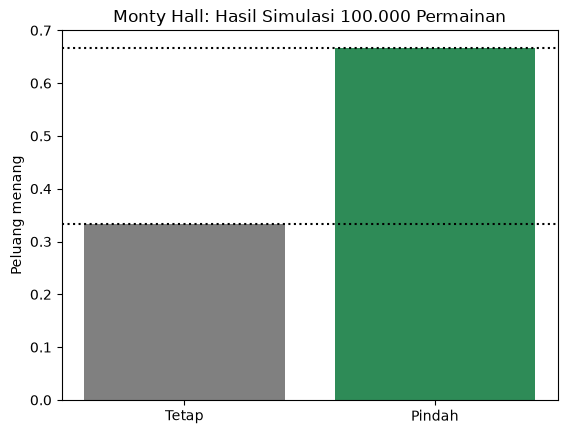

In [11]:
def main_monty(pindah, n=100_000):
    menang = 0
    for _ in range(n):
        pintu = [0, 1, 2]
        hadiah = random.choice(pintu)
        pilihan = random.choice(pintu)
        # pembawa acara membuka pintu kosong yang tidak dipilih pemain
        dibuka = random.choice([p for p in pintu if p != pilihan and p != hadiah])
        if pindah:
            pilihan = [p for p in pintu if p != pilihan and p != dibuka][0]
        menang += (pilihan == hadiah)
    return menang / n

p_tetap = main_monty(pindah=False)
p_pindah = main_monty(pindah=True)
print(f"P(menang | tetap)  simulasi = {p_tetap:.4f}  (teori 1/3 = {1/3:.4f})")
print(f"P(menang | pindah) simulasi = {p_pindah:.4f}  (teori 2/3 = {2/3:.4f})")

plt.bar(["Tetap", "Pindah"], [p_tetap, p_pindah], color=["gray", "seagreen"])
plt.axhline(1/3, color="black", linestyle=":")
plt.axhline(2/3, color="black", linestyle=":")
plt.ylabel("Peluang menang")
plt.title("Monty Hall: Hasil Simulasi 100.000 Permainan")
plt.show()

## P11. Hukum Bilangan Besar: Pembagian Request oleh Load Balancer

**Soal:** Sebuah load balancer mengirim setiap request ke salah satu dari 4 server secara acak dengan peluang sama. Simulasikan 50.000 request dan amati bagaimana proporsi request yang diterima setiap server berubah seiring bertambahnya jumlah request.

**Perhitungan manual:**

- Secara teori setiap server menerima request dengan peluang 1/4 = 0,25.
- Menurut hukum bilangan besar, proporsi request tiap server akan mendekati 0,25 jika jumlah request makin besar.

    20 request -> proporsi S1-S4 = [0.1  0.45 0.2  0.25], selisih terbesar dari 0,25 = 0.2000
   200 request -> proporsi S1-S4 = [0.23  0.255 0.24  0.275], selisih terbesar dari 0,25 = 0.0250
  2000 request -> proporsi S1-S4 = [0.2475 0.2415 0.2535 0.2575], selisih terbesar dari 0,25 = 0.0085
 50000 request -> proporsi S1-S4 = [0.2499 0.2493 0.2506 0.2503], selisih terbesar dari 0,25 = 0.0007


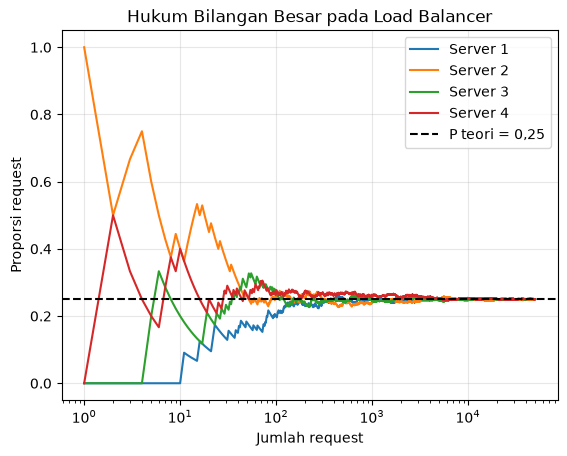

In [12]:
n = 50_000
server = rng.integers(1, 5, n)   # nomor server 1 sampai 4
urutan = np.arange(1, n + 1)

for m in [20, 200, 2000, 50000]:
    prop = [np.mean(server[:m] == s) for s in range(1, 5)]
    print(f"{m:>6} request -> proporsi S1-S4 = {np.round(prop, 4)}, "
          f"selisih terbesar dari 0,25 = {max(abs(p - 0.25) for p in prop):.4f}")

for s in range(1, 5):
    plt.semilogx(urutan, np.cumsum(server == s) / urutan, label=f"Server {s}")
plt.axhline(0.25, color="black", linestyle="--", label="P teori = 0,25")
plt.xlabel("Jumlah request")
plt.ylabel("Proporsi request")
plt.title("Hukum Bilangan Besar pada Load Balancer")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## P12. Probabilitas Empiris dari Data Rating Aplikasi

**Soal:** Sebuah aplikasi menerima 500 ulasan dengan rincian: bintang 1 sebanyak 40, bintang 2 sebanyak 35, bintang 3 sebanyak 75, bintang 4 sebanyak 150, dan bintang 5 sebanyak 200. Tentukan peluang empiris setiap rating, peluang rating minimal 4, serta nilai harapan dan varians rating. Gunakan peluang empiris tersebut untuk menghitung peluang minimal 8 dari 10 ulasan baru memberi rating minimal 4, lalu amati perkiraan peluang dari sampel berukuran berbeda.

**Perhitungan manual:**

- Peluang empiris = frekuensi / jumlah data, misalnya P(bintang 5) = 200/500 = 0,40 dan P(rating >= 4) = 350/500 = 0,70.
- E(X) = (1 x 40 + 2 x 35 + 3 x 75 + 4 x 150 + 5 x 200)/500 = 1935/500 = 3,87.
- E(X^2) = 8255/500 = 16,51 sehingga Var(X) = 16,51 - 3,87^2 = 1,5331.
- Dengan p = 0,7 untuk 10 ulasan: P(minimal 8) = C(10,8)(0,7)^8(0,3)^2 + C(10,9)(0,7)^9(0,3) + (0,7)^10 = 0,3828.

Peluang empiris tiap rating:
bintang
1    0.08
2    0.07
3    0.15
4    0.30
5    0.40

P(rating >= 4) = 0.7000
E(rating)      = 3.8700 | Series.mean()      = 3.8700
Var(rating)    = 1.5331 | Series.var(ddof=0) = 1.5331

P(minimal 8 dari 10 ulasan baru >= 4) = 0.3828
Sampel  20 ulasan -> P(rating >= 4) = 0.8500
Sampel 100 ulasan -> P(rating >= 4) = 0.7600
Sampel 400 ulasan -> P(rating >= 4) = 0.6950


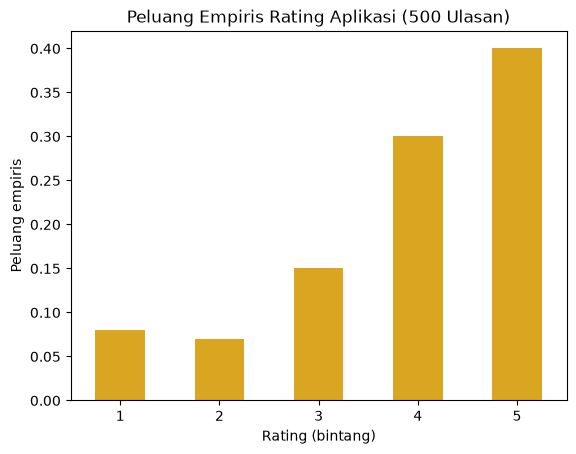

In [13]:
frek = {1: 40, 2: 35, 3: 75, 4: 150, 5: 200}
ulasan = pd.Series([b for b, f in frek.items() for _ in range(f)], name="bintang")

p_emp = ulasan.value_counts(normalize=True).sort_index()
print("Peluang empiris tiap rating:")
print(p_emp.to_string())

p_puas = (ulasan >= 4).mean()
e_rating = (p_emp.index * p_emp).sum()
var_rating = (p_emp.index ** 2 * p_emp).sum() - e_rating ** 2
print(f"\nP(rating >= 4) = {p_puas:.4f}")
print(f"E(rating)      = {e_rating:.4f} | Series.mean()      = {ulasan.mean():.4f}")
print(f"Var(rating)    = {var_rating:.4f} | Series.var(ddof=0) = {ulasan.var(ddof=0):.4f}")

# Peluang empiris dipakai sebagai p untuk 10 ulasan baru
p_8 = sum(math.comb(10, k) * p_puas**k * (1 - p_puas)**(10 - k) for k in range(8, 11))
print(f"\nP(minimal 8 dari 10 ulasan baru >= 4) = {p_8:.4f}")

# Perkiraan peluang dari sampel acak berbagai ukuran
for n in [20, 100, 400]:
    sampel = ulasan.sample(n, random_state=7)
    print(f"Sampel {n:>3} ulasan -> P(rating >= 4) = {(sampel >= 4).mean():.4f}")

p_emp.plot(kind="bar", color="goldenrod")
plt.xticks(rotation=0)
plt.xlabel("Rating (bintang)")
plt.ylabel("Peluang empiris")
plt.title("Peluang Empiris Rating Aplikasi (500 Ulasan)")
plt.show()